<a href="https://colab.research.google.com/github/Aryansinghparmar2321/OSSLab_241B048/blob/main/RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [17]:
vocab_size = 10000
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("First review:", X_train[0])
print("First label:", y_train[0])

Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]

In [18]:
word_index = imdb.get_word_index()
reverse_word_index = {
    value + 3: key
    for key, value in word_index.items()
}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<OOV>"

def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i, "?")
        for i in encoded_review
    )
df = pd.DataFrame({
    "Review": [decode_review(review) for review in X_train],
    "Review_Length": [len(review) for review in X_train],
    "Sentiment": y_train
})
df["Sentiment"] = df["Sentiment"].map({
    0: "Negative",
    1: "Positive"
})
print(df.head(10))

                                              Review  Review_Length Sentiment
0  <START> this film was just brilliant casting l...            218  Positive
1  <START> big hair big boobs bad music and a gia...            189  Negative
2  <START> this has to be one of the worst films ...            141  Negative
3  <START> the <OOV> <OOV> at storytelling the tr...            550  Positive
4  <START> worst mistake of my life br br i picke...            147  Negative
5  <START> begins better than it ends funny that ...             43  Negative
6  <START> lavish production values and solid per...            123  Positive
7  <START> the <OOV> tells the story of the four ...            562  Negative
8  <START> just got out and cannot believe what a...            233  Positive
9  <START> this movie has many problem associated...            130  Negative


In [19]:
print(df.shape)
print("\nDataset Information:")
print(df.info())
print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())
print("\nStatistical Summary:")
print(df["Review_Length"].describe())

(25000, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Review         25000 non-null  object
 1   Review_Length  25000 non-null  int64 
 2   Sentiment      25000 non-null  object
dtypes: int64(1), object(2)
memory usage: 586.1+ KB
None

Sentiment Distribution:
Sentiment
Positive    12500
Negative    12500
Name: count, dtype: int64

Statistical Summary:
count    25000.000000
mean       238.713640
std        176.497204
min         11.000000
25%        130.000000
50%        178.000000
75%        291.000000
max       2494.000000
Name: Review_Length, dtype: float64


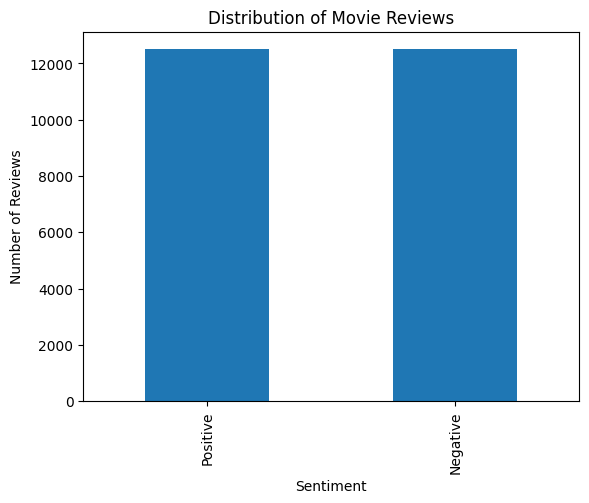

In [20]:
df["Sentiment"].value_counts().plot(
    kind="bar",
    title="Distribution of Movie Reviews"
)
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [21]:
max_length = 200
X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [22]:
model = Sequential()
model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=32,
        input_length=max_length
    )
)
model.add(
    SimpleRNN(64)
)
model.add(
    Dropout(0.3)
)
model.add(
    Dense(1, activation="sigmoid")
)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("RNN model compiled successfully!")

RNN model compiled successfully!


In [24]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.4983 - loss: 0.6965 - val_accuracy: 0.5066 - val_loss: 0.6930
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.5796 - loss: 0.6737 - val_accuracy: 0.4990 - val_loss: 0.7063
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.6370 - loss: 0.6087 - val_accuracy: 0.5018 - val_loss: 0.7498
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7022 - loss: 0.4925 - val_accuracy: 0.5110 - val_loss: 0.8329
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7447 - loss: 0.3986 - val_accuracy: 0.5012 - val_loss: 0.9654


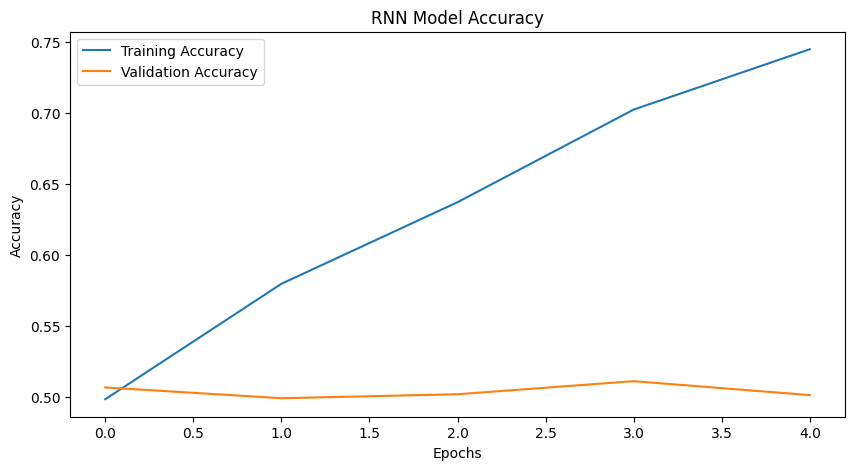

In [25]:
plt.figure(figsize=(10, 5))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("RNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

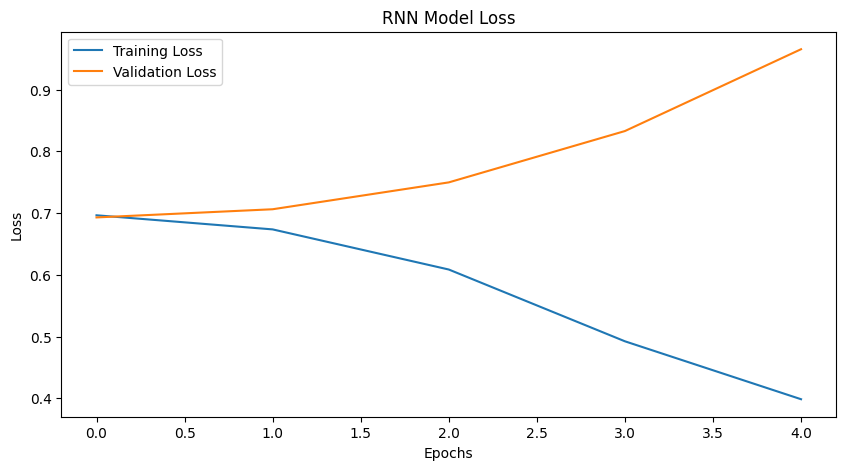

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.title("RNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [27]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test
)
print("Testing Loss:", test_loss)
print("Testing Accuracy:", test_accuracy)
print("Testing Accuracy (%):", test_accuracy * 100)

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5002 - loss: 0.9389
Testing Loss: 0.9388550519943237
Testing Accuracy: 0.5001599788665771
Testing Accuracy (%): 50.015997886657715


In [28]:
y_pred_prob = model.predict(X_test_pad)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("First 10 Actual Labels:")
print(y_test[:10])
print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step
First 10 Actual Labels:
[0 1 1 0 1 1 1 0 0 1]

First 10 Predicted Labels:
[0 0 0 1 0 0 0 1 0 1]


In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Accuracy: 0.50016

Confusion Matrix:
[[7247 5253]
 [7243 5257]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      0.58      0.54     12500
    Positive       0.50      0.42      0.46     12500

    accuracy                           0.50     25000
   macro avg       0.50      0.50      0.50     25000
weighted avg       0.50      0.50      0.50     25000



In [32]:
def predict_sentiment(review):
    words = review.lower().split()
    encoded = [1]
    for word in words:
        index = word_index.get(word)
        if index is None or index + 3 >= vocab_size:
            encoded.append(2)
        else:
            encoded.append(index + 3)
    padded = pad_sequences([encoded], maxlen=max_length, padding="post", truncating="post")
    prediction = model.predict(padded, verbose=0)[0][0]
    if prediction >= 0.5:
        print("Predicted Sentiment: Positive")
    else:
        print("Predicted Sentiment: Negative")
    print("Prediction Probability:", prediction)

review1 = "This movie is excellent and wonderful. I really enjoyed it."
predict_sentiment(review1)

review2 = "This movie is boring and disappointing. I did not like it."
predict_sentiment(review2)

Predicted Sentiment: Negative
Prediction Probability: 0.47521934
Predicted Sentiment: Negative
Prediction Probability: 0.47887948
